In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from europa_eutectic.gaia_sim import GaiaSim
from europa_eutectic.util import colors


AUX_BASE = Path("../../data")
shell_visc_sims = [json_path for json_path in Path(AUX_BASE / "shell_visc").glob("*.json")]
shell_complex_rheo_sims = [json_path for json_path in Path(AUX_BASE / "shell_complex_rheo").glob("*.json")]
constK_varA_sims = [json_path for json_path in Path(AUX_BASE / "shell_thermal_cond_expan" / "constK_varA").glob("*.json")]
varK_constA_sims= [json_path for json_path in Path(AUX_BASE  / "shell_thermal_cond_expan" / "varK_constA").glob("*.json")]
varK_varA_sims= [json_path for json_path in Path(AUX_BASE    / "shell_thermal_cond_expan" / "varK_varA").glob("*.json")]
shell_tidal_sims = [json_path for json_path in Path(AUX_BASE / "shell_tidal").glob("*.json")]

base_cmap = sns.color_palette("icy_moon_2", as_cmap = True) # My custom colormap

# Collection of Eutectics 

#### for both Zolotov and NaCl

# Data Wrangling

In [2]:
shell_visc_sims_sorted = sorted(shell_visc_sims, key=lambda x: int(x.stem.split("_")[-3].replace("D", "").replace("km", "")))
shell_visc_sims_sorted_v2 = sorted(shell_visc_sims_sorted, key=lambda x: int(x.stem.split("_")[-2].replace("eta1e+", "")))

shell_visc_20_60 = [GaiaSim.load_from_json(sim_path) for sim_path in shell_visc_sims_sorted_v2 if "D20km" in sim_path.name or "D60km" in sim_path.name]

reg2_169_RR0.987186_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_D20km_eta1e+12/.
reg2_169_RR0.987186_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_20km_eta1e+12_small_test/.
reg2_169_RR0.987186_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_20km_eta1e+12/.


KeyboardInterrupt: 

In [10]:
df_list = []
avg_df_list = []


for sim in shell_visc_20_60:

    eutectic = sim.eutectics[0] # only zolotov
    eut_dict = {}


    eut_dict["Depth to Eutectic (km)"] = eutectic.depth_to_eutectic/1000 # km
    eut_dict["Distance Along Equator (km)"] = eutectic.distance_along_equator/1000 # km
    eut_dict["Eutectic Temperature (K)"] = [eutectic.eutectic_temperature for _ in range(len(eutectic.depth_to_eutectic))]
    eut_dict["D (km)"] = sim.D
    eut_dict["log(η_ref) (Pa·s)"] = sim.eta_ref

    df_list.append(pd.DataFrame(eut_dict))


    avg_df_list.append(pd.DataFrame({
        "Depth to Eutectic (km)": np.full(
            len(eutectic.depth_to_eutectic),
            np.mean(eutectic.depth_to_eutectic) / 1000,
        ),
        "Distance Along Equator (km)": eutectic.distance_along_equator/1000,
        "Eutectic Temperature (K)": [eutectic.eutectic_temperature for _ in range(len(eutectic.depth_to_eutectic))],
        "D (km)": [sim.D for _ in range(len(eutectic.depth_to_eutectic))],
        "log(η_ref) (Pa·s)": [sim.eta_ref for _ in range(len(eutectic.depth_to_eutectic))],
    }))
        

eut_df = pd.concat(df_list)
avg_eut_df = pd.concat(avg_df_list)

eut_df

,Depth to Eutectic (km),Distance Along Equator (km),Eutectic Temperature (K),D (km),log(η_ref) (Pa·s)
0,2.652265,0.000000,237.15,20.0,12.0
1,2.652265,0.119087,237.15,20.0,12.0
2,2.653750,0.238174,237.15,20.0,12.0
3,2.656462,0.357260,237.15,20.0,12.0
4,2.660305,0.476347,237.15,20.0,12.0
...,...,...,...,...,...
863,38.131924,195.456458,237.15,60.0,15.0
864,38.400724,195.682943,237.15,60.0,15.0
865,38.592355,195.909428,237.15,60.0,15.0
866,38.692156,196.135913,237.15,60.0,15.0


D (km) = 20
D (km) = 60


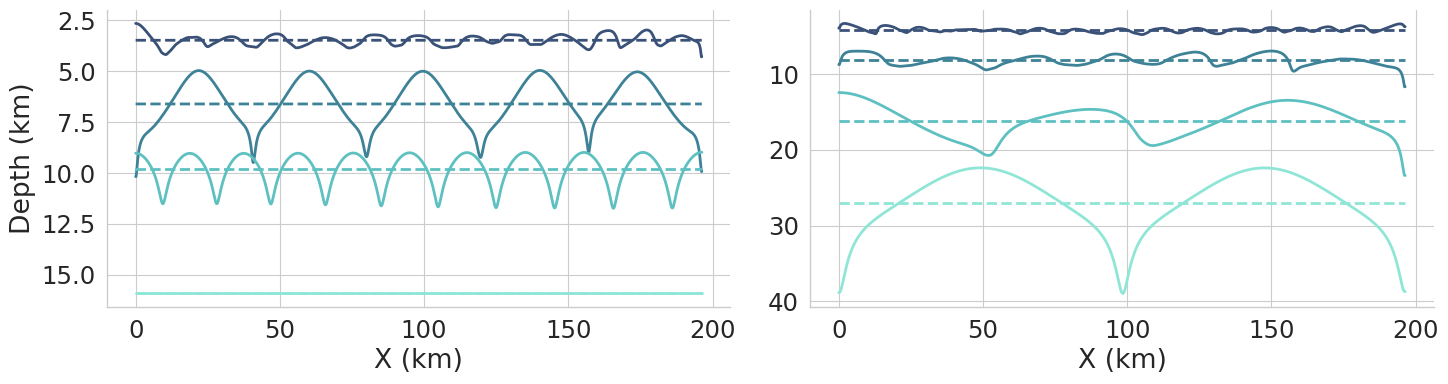

In [11]:
eut_df["D (km)"] = eut_df["D (km)"].astype(int)
eut_df["log(η_ref) (Pa·s)"] = eut_df["log(η_ref) (Pa·s)"].astype(int)
eut_df.rename({"Distance Along Equator (km)": "X (km)", "Depth to Eutectic (km)": "Depth (km)"}, axis=1, inplace=True)
avg_eut_df.rename({"Distance Along Equator (km)": "X (km)", "Depth to Eutectic (km)": "Depth (km)"}, axis=1, inplace=True)

hue_order = sorted(eut_df["log(η_ref) (Pa·s)"].unique())
n_lines = len(hue_order)
positions = np.linspace(0.2, 0.85, n_lines)
line_palette = [base_cmap(pos) for pos in positions]
color_lookup = dict(zip(hue_order, line_palette))



sns.set_context("paper", font_scale=2)
sns.set_style("whitegrid")
g = sns.relplot(
    data=eut_df,
    kind="line",                    # Use line instead of scatter
    x="X (km)",
    y="Depth (km)",
    col="D (km)",                   # Facets by column
    hue="log(η_ref) (Pa·s)",        # Colors by viscosity
    hue_order=hue_order,
    palette=color_lookup,
    linewidth=2,
    height=4.5,
    aspect=1.4,
    facet_kws={"sharey": False}
)

for ax in g.axes.flat:
    print(ax.get_title())
    current_col_val = int(ax.get_title().split(" ")[-1])
    
    subset_avg = avg_eut_df[avg_eut_df["D (km)"] == current_col_val] # Filter for this column
    
    for eutectic_temp, group_data in subset_avg.groupby("log(η_ref) (Pa·s)"):
        # Plot dashed line
        ax.plot(
            group_data["X (km)"],
            group_data["Depth (km)"],
            linestyle="--",
            color=color_lookup.get(eutectic_temp, "black"), # Fallback to black if key missing
            linewidth=2
        )

if g._legend:
    g._legend.remove()
    g._legend = None

# --- Final Formatting ---
for ax in g.axes.flat:
    ax.invert_yaxis()

plt.tight_layout()
g.set_titles(col_template="")

g.savefig("../images/figure2.png", transparent=True, dpi=300)
plt.show()

# Complete List (Supplemental)

### 2x5, columns are eutectic interfaces, save each row seperately like above

In [12]:
shell_visc_sims_sorted = sorted(shell_visc_sims, key=lambda x: int(x.stem.split("_")[-3].replace("D", "").replace("km", "")))
shell_visc_sims_sorted_v2 = sorted(shell_visc_sims_sorted, key=lambda x: int(x.stem.split("_")[-2].replace("eta1e+", "")))

shell_visc_sims = [GaiaSim.load_from_json(sim_path) for sim_path in shell_visc_sims_sorted_v2]

shell_visc_D_sims = {20: [], 30: [], 40: [], 50: [], 60: []}
for sim in shell_visc_sims:
    if int(sim.D) in shell_visc_D_sims.keys():
        shell_visc_D_sims[int(sim.D)].append(sim)
shell_visc_D_sims

reg2_270_RR0.980779_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_30km_eta1e+12/.
reg2_270_RR0.980779_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_D30km_eta1e+12/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_40km_eta1e+12/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_D40km_eta1e+12/.
reg2_270_RR0.967965_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_50km_eta1e+12/.
reg2_270_RR0.967965_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_D50km_eta1e+12/.
reg2_231_RR0.980779_P0.02.grid  PATH /scratch/ws/7/byrn_wi-europa_eutectic/Europa_D30km_eta1e+13/.
reg2_270_RR0.974372_P0.02.grid  PATH /scratch/ws/7/byrn_wi-europa_eutectic/Europa_D40km_eta1e+13/.
reg2_270_RR0.967965_P0.02.grid  PATH /scratch/ws/7/byrn_wi-europa_eutectic/Europa_D50km_eta1e+13/.
reg2_186_RR0.980779_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/Europa_30km_eta1e+14/.
reg2_270_RR0.9

{20: [GaiaSimcaseID='Europa_D20km_eta1e+12', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_visc', 
              "Shell thickness"=20000.00 (m),
              "log_10(eta_ref)"=12.00 log_10(Pa s),
              Ra=193078530.9746666, 
              final_time=23.0668 Myr),
  GaiaSimcaseID='Europa_D20km_eta1e+13', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_visc', 
              "Shell thickness"=20000.00 (m),
              "log_10(eta_ref)"=13.00 log_10(Pa s),
              Ra=19307853.09746666, 
              final_time=50.2084 Myr),
  GaiaSimcaseID='Europa_D20km_eta1e+14', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_visc', 
              "Shell thickness"=20000.00 (m),
              "log_10(eta_ref)"=14.00 log_10(Pa s),
              Ra=1930785.3097466659, 
              final_time=59.8009 Myr),
  GaiaSimcaseID='Europa_D20km_eta1e+15', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_visc', 
              "Shell thickness"=20000.00 (m),
       

In [13]:
df_list = []
avg_df_list = []


for sim in shell_visc_sims:
    for eutectic in sim.eutectics:
        eut_dict = {}

        eut_dict["Depth to Eutectic (km)"] = eutectic.depth_to_eutectic/1000 # km
        eut_dict["Distance Along Equator (km)"] = eutectic.distance_along_equator/1000 # km
        eut_dict["Eutectic Temperature (K)"] = [eutectic.eutectic_temperature for _ in range(len(eutectic.depth_to_eutectic))]
        eut_dict["D (km)"] = sim.D
        eut_dict["log(η_ref) (Pa·s)"] = sim.eta_ref
        eut_dict["Eutectic Type"] = eutectic.eutectic_temperature

        df_list.append(pd.DataFrame(eut_dict))


        avg_df_list.append(pd.DataFrame({
            "Depth to Eutectic (km)": np.full(
                len(eutectic.depth_to_eutectic),
                np.mean(eutectic.depth_to_eutectic) / 1000,
            ),
            "Distance Along Equator (km)": eutectic.distance_along_equator/1000,
            "Eutectic Temperature (K)": [eutectic.eutectic_temperature for _ in range(len(eutectic.depth_to_eutectic))],
            "D (km)": [sim.D for _ in range(len(eutectic.depth_to_eutectic))],
            "log(η_ref) (Pa·s)": [sim.eta_ref for _ in range(len(eutectic.depth_to_eutectic))],
            "Eutectic Type": eutectic.eutectic_temperature
        }))

        

eut_df = pd.concat(df_list)
avg_eut_df = pd.concat(avg_df_list)

eut_df["D (km)"] = eut_df["D (km)"].astype(int)
eut_df["log(η_ref) (Pa·s)"] = eut_df["log(η_ref) (Pa·s)"].astype(int)
eut_df.rename({"Distance Along Equator (km)": "X (km)", "Depth to Eutectic (km)": "Depth (km)"}, axis=1, inplace=True)
avg_eut_df.rename({"Distance Along Equator (km)": "X (km)", "Depth to Eutectic (km)": "Depth (km)"}, axis=1, inplace=True)

eut_df

,Depth (km),X (km),Eutectic Temperature (K),D (km),log(η_ref) (Pa·s),Eutectic Type
0,2.652265,0.000000,237.15,20,12,237.15
1,2.652265,0.119087,237.15,20,12,237.15
2,2.653750,0.238174,237.15,20,12,237.15
3,2.656462,0.357260,237.15,20,12,237.15
4,2.660305,0.476347,237.15,20,12,237.15
...,...,...,...,...,...,...
863,58.694835,195.456458,252.05,60,15,252.05
864,58.698079,195.682943,252.05,60,15,252.05
865,58.700146,195.909428,252.05,60,15,252.05
866,58.701122,196.135913,252.05,60,15,252.05


Eutectic Type = 237.15
Eutectic Type = 252.05


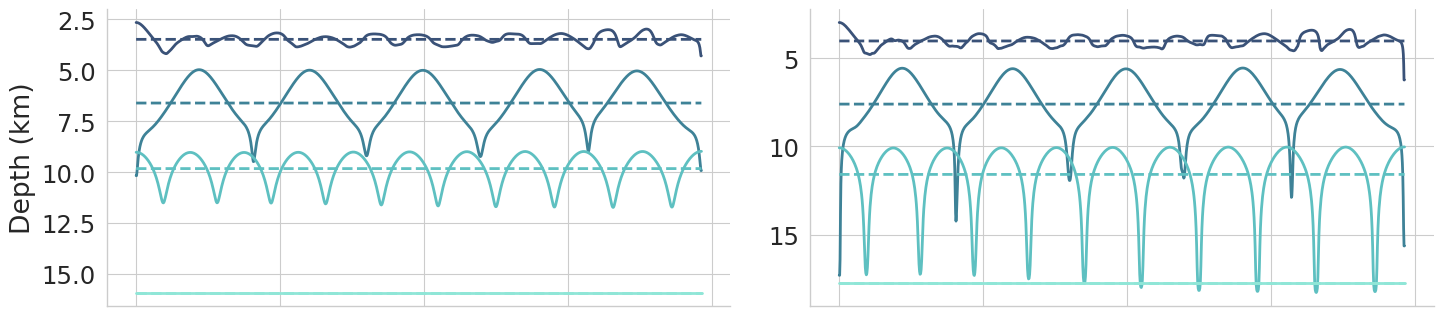

Eutectic Type = 237.15
Eutectic Type = 252.05


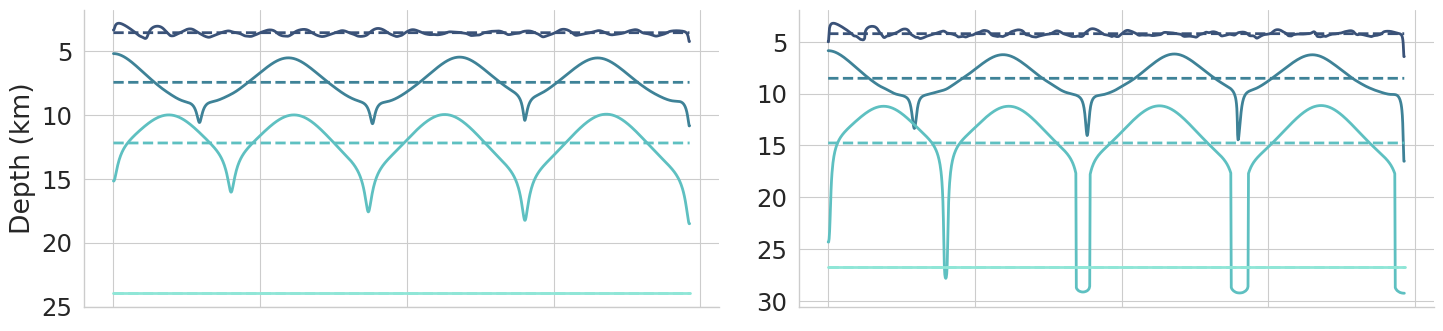

Eutectic Type = 237.15
Eutectic Type = 252.05


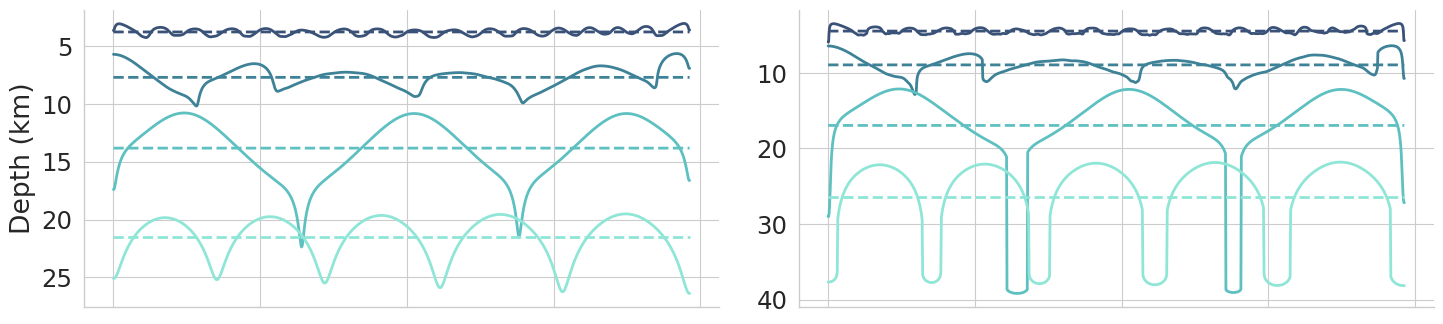

Eutectic Type = 237.15
Eutectic Type = 252.05


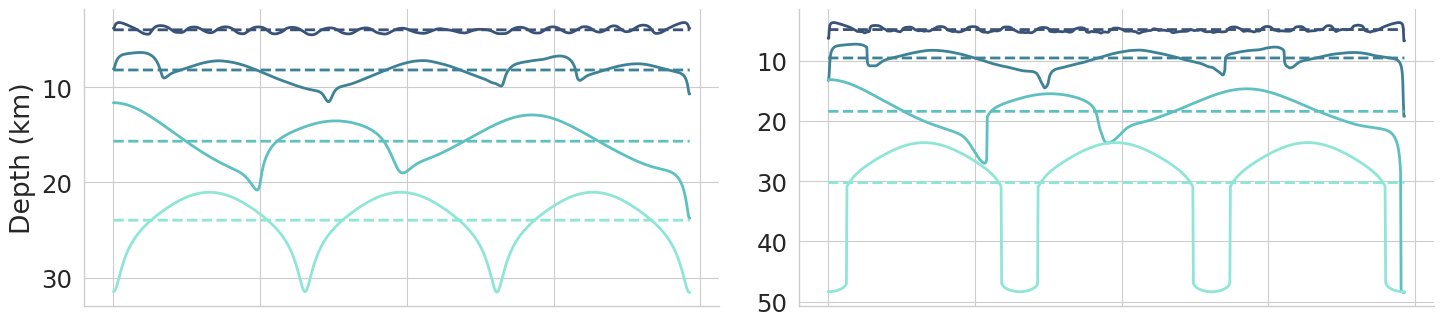

Eutectic Type = 237.15
Eutectic Type = 252.05


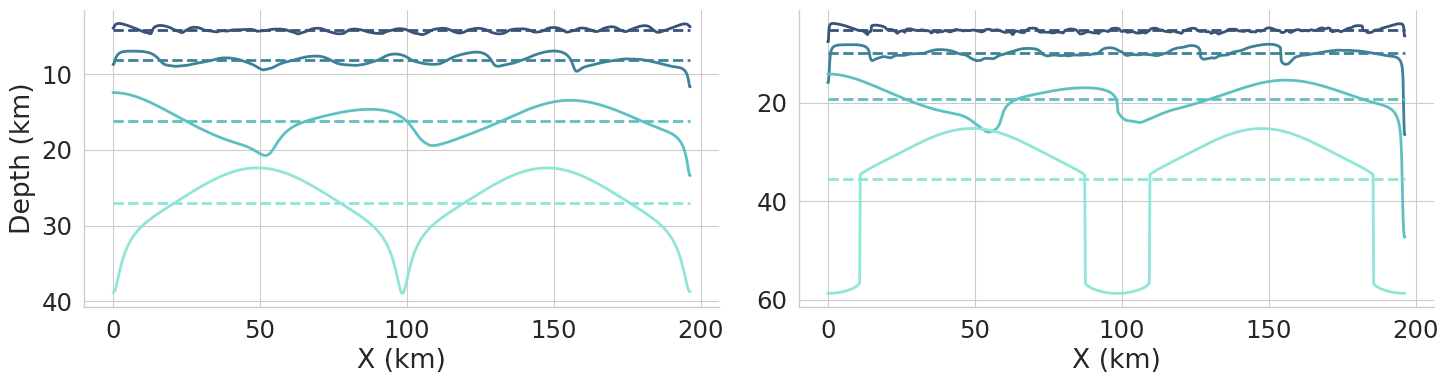

In [14]:
hue_order = sorted(eut_df["log(η_ref) (Pa·s)"].unique())
n_lines = len(hue_order)
positions = np.linspace(0.2, 0.85, n_lines)
line_palette = [base_cmap(pos) for pos in positions]
color_lookup = dict(zip(hue_order, line_palette))

for D, sims in shell_visc_D_sims.items():
    shell_eut_df = eut_df[eut_df["D (km)"] == D]
    shell_avg_eut_df = avg_eut_df[avg_eut_df["D (km)"] == D]
    sns.set_context("paper", font_scale=2)
    sns.set_style("whitegrid")

    g = sns.relplot(
    data=shell_eut_df,
    kind="line",                    # Use line instead of scatter
    x="X (km)",
    y="Depth (km)",
    col="Eutectic Type",                   # Facets by column
    hue="log(η_ref) (Pa·s)",        # Colors by viscosity
    hue_order=hue_order,
    palette=color_lookup,
    linewidth=2,
    height=4.5,
    aspect=1.4,
    facet_kws={"sharey": False}
    )

    for ax in g.axes.flat:
        print(ax.get_title())
        current_col_val = float(ax.get_title().split(" ")[-1])

        subset_avg = shell_avg_eut_df[shell_avg_eut_df["Eutectic Type"] == current_col_val] # Filter for this column

        for eutectic_temp, group_data in subset_avg.groupby("log(η_ref) (Pa·s)"):
            # Plot dashed line
            ax.plot(
                group_data["X (km)"],
                group_data["Depth (km)"],
                linestyle="--",
                color=color_lookup.get(eutectic_temp, "black"), # Fallback to black if key missing
                linewidth=2
            )
    
    if g._legend:
        g._legend.remove()
        g._legend = None
    
    # --- Final Formatting ---
    for ax in g.axes.flat:
        ax.invert_yaxis()
    plt.tight_layout()
    g.set_titles(col_template="")

    if D != 60:
        g.set_xlabels("")
        g.set_xticklabels([])
        g.set(xlim=(-10, shell_eut_df["X (km)"].max()+10))

    g.savefig(f"fig2_D{D}.png", dpi = 200, transparent = True)
    plt.show()    

# Complete List (Thesis)

### 2x5, columns are eutectic interfaces, save each row seperately like above

In [4]:
#########################################################################################################
complex_sims = shell_complex_rheo_sims + constK_varA_sims + varK_constA_sims + varK_varA_sims + shell_tidal_sims
complex_sims_sorted = sorted(complex_sims, key=lambda x: int(x.stem.split("_")[1].replace("D", "").replace("km", "")))

complex_sims = [GaiaSim.load_from_json(sim_path) for sim_path in complex_sims_sorted]

complex_D_sims = {20: [], 30: [], 40: [], 50: [], 60: []}
for sim in complex_sims:
    if int(sim.D) in complex_D_sims.keys():
        complex_D_sims[int(sim.D)].append(sim)
complex_D_sims

reg2_136_RR0.987186_P0.02.grid  PATH /scratch/ws/7/byrn_wi-europa_eutectic/Europa_D_1e13_thermal_comlex_rheo/Europa_D20km_eta2e-04/.
reg2_136_RR0.987186_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic_2/Europa_D_1e13_thermal_comlex_rheo/Europa_D20km_eta2e-04/.
reg2_139_RR0.987186_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/constK_varA/Europa_D20km_eta1e+13/.
reg2_139_RR0.987186_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_constA/Europa_D20km_eta1e+13/.
reg2_139_RR0.987186_P0.02.grid  PATH /scratch/ws/m2/byrn_wi-europa_eutectic/var_thermal/varK_varA/Europa_D20km_eta1e+13/.
reg2_139_RR0.987186_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic/shell_tidal/Europa_D20km_eta1e+13_Tides/.
reg2_227_RR0.980779_P0.02.grid  PATH /scratch/ws/7/byrn_wi-europa_eutectic/Europa_D_1e13_thermal_comlex_rheo/Europa_D30km_eta2e-04/.
reg2_227_RR0.980779_P0.02.grid  PATH /scratch/ws25/byrn_wi-europa_eutectic_2/Europa_D_1e13_thermal_comlex_rheo/E

{20: [GaiaSimcaseID='Europa_D20km_eta2e-04', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_complex_rheo', 
              "Shell thickness"=20000.00 (m),
              "log_10(eta_ref)"=13.00 log_10(Pa s),
              Ra=19307853.09746666, 
              final_time=157.403 Myr),
  GaiaSimcaseID='Europa_D20km_eta1e+13', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_thermal_cond_expan/constK_varA', 
              "Shell thickness"=20000.00 (m),
              "log_10(eta_ref)"=13.00 log_10(Pa s),
              Ra=19307853.09746666, 
              final_time=63.5099 Myr),
  GaiaSimcaseID='Europa_D20km_eta1e+13', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_thermal_cond_expan/varK_constA', 
              "Shell thickness"=20000.00 (m),
              "log_10(eta_ref)"=13.00 log_10(Pa s),
              Ra=19307853.09746666, 
              final_time=203.232 Myr),
  GaiaSimcaseID='Europa_D20km_eta1e+13', 
              parent_dir='/plp_user/byrn_wi/scr1/shell_th

In [5]:
###############################################################################################
df_list = []
avg_df_list = []


for sim in complex_sims:
    for eutectic in sim.eutectics:
        eut_dict = {}

        eut_dict["Depth to Eutectic (km)"] = eutectic.depth_to_eutectic/1000 # km
        eut_dict["Distance Along Equator (km)"] = eutectic.distance_along_equator/1000 # km
        eut_dict["Eutectic Temperature (K)"] = [eutectic.eutectic_temperature for _ in range(len(eutectic.depth_to_eutectic))]
        eut_dict["D (km)"] = sim.D
        eut_dict["Parameter Folder"] = sim.parent_dir.name
        eut_dict["Eutectic Type"] = eutectic.eutectic_temperature

        df_list.append(pd.DataFrame(eut_dict))


        avg_df_list.append(pd.DataFrame({
            "Depth to Eutectic (km)": np.full(
                len(eutectic.depth_to_eutectic),
                np.mean(eutectic.depth_to_eutectic) / 1000,
            ),
            "Distance Along Equator (km)": eutectic.distance_along_equator/1000,
            "Eutectic Temperature (K)": [eutectic.eutectic_temperature for _ in range(len(eutectic.depth_to_eutectic))],
            "D (km)": [sim.D for _ in range(len(eutectic.depth_to_eutectic))],
            "Parameter Folder": [sim.parent_dir.name for _ in range(len(eutectic.depth_to_eutectic))],
            "Eutectic Type": eutectic.eutectic_temperature
        }))

        

complex_eut_df = pd.concat(df_list)
complex_avg_eut_df = pd.concat(avg_df_list)

complex_eut_df["D (km)"] = complex_eut_df["D (km)"].astype(int)
complex_eut_df.rename({"Distance Along Equator (km)": "X (km)", "Depth to Eutectic (km)": "Depth (km)"}, axis=1, inplace=True)
complex_avg_eut_df.rename({"Distance Along Equator (km)": "X (km)", "Depth to Eutectic (km)": "Depth (km)"}, axis=1, inplace=True)

complex_eut_df

,Depth (km),X (km),Eutectic Temperature (K),D (km),Parameter Folder,Eutectic Type
0,10.954756,0.000000,237.15,20,shell_complex_rheo,237.15
1,10.954756,0.148007,237.15,20,shell_complex_rheo,237.15
2,10.829122,0.296014,237.15,20,shell_complex_rheo,237.15
3,10.643760,0.444022,237.15,20,shell_complex_rheo,237.15
4,10.447612,0.592029,237.15,20,shell_complex_rheo,237.15
...,...,...,...,...,...,...
863,9.047702,195.456458,252.05,60,shell_tidal,252.05
864,9.577549,195.682943,252.05,60,shell_tidal,252.05
865,10.719943,195.909428,252.05,60,shell_tidal,252.05
866,12.457123,196.135913,252.05,60,shell_tidal,252.05


['varK_constA', 'constK_varA', 'varK_varA', 'shell_complex_rheo', 'shell_tidal']


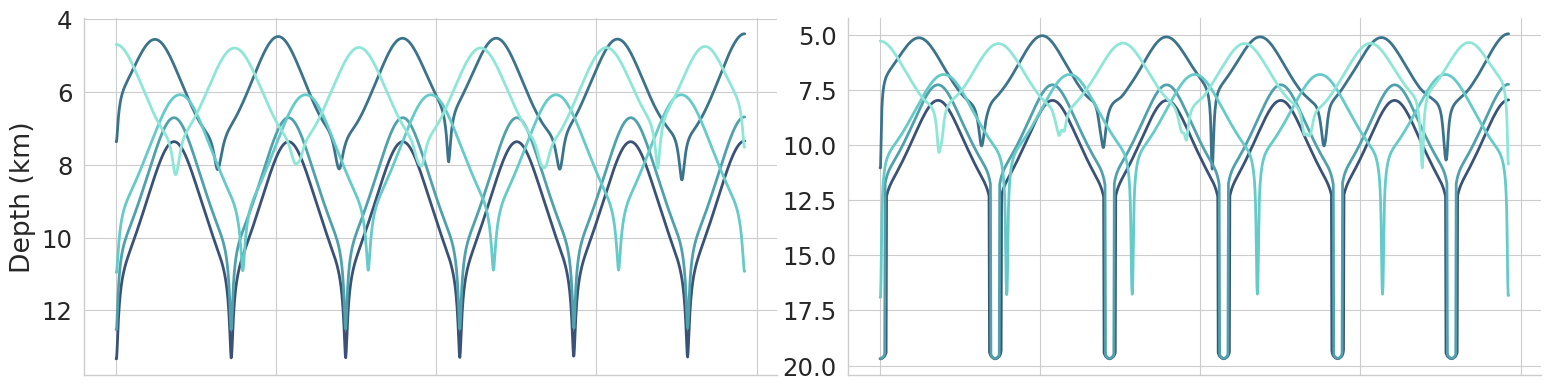

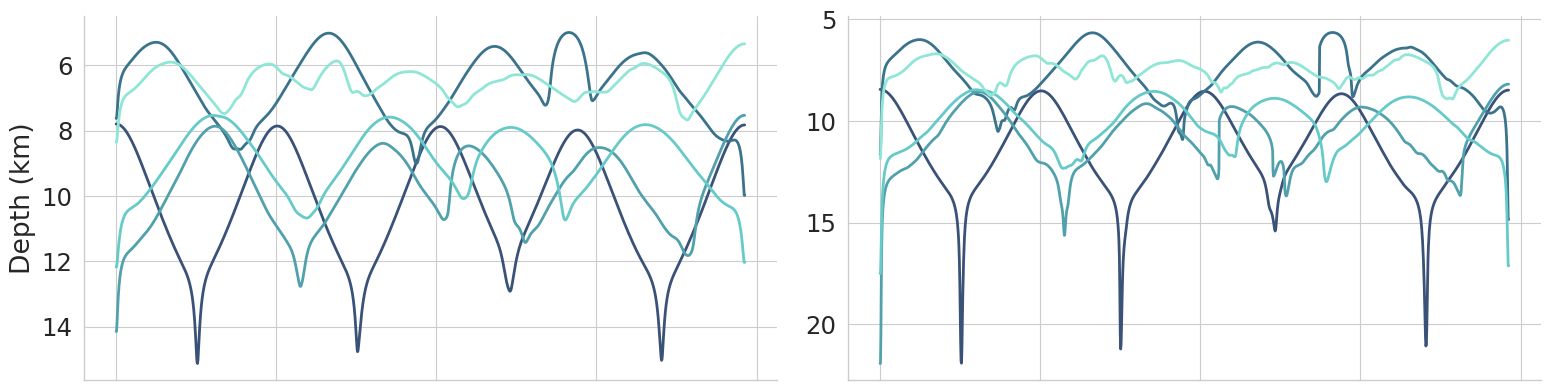

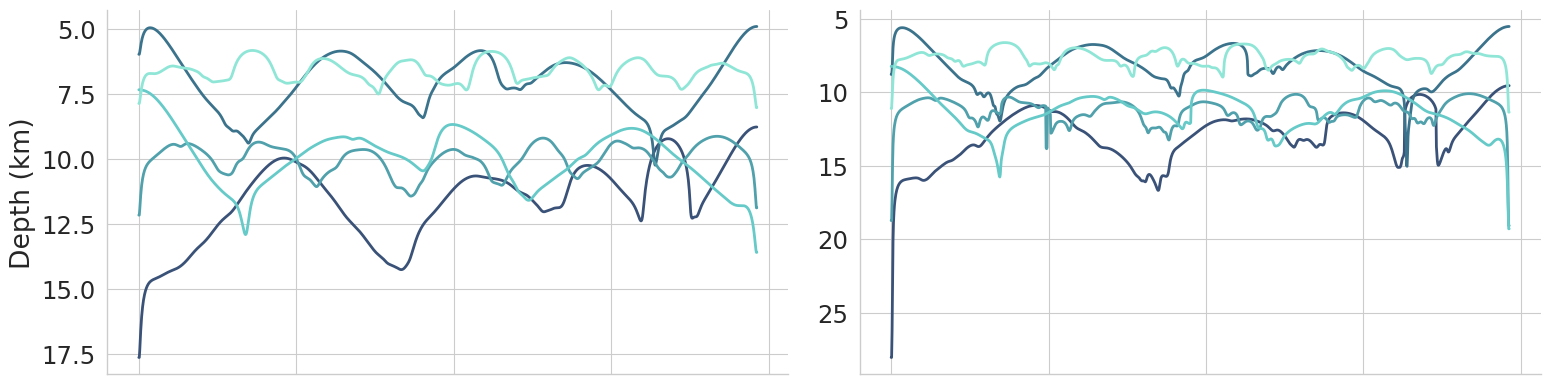

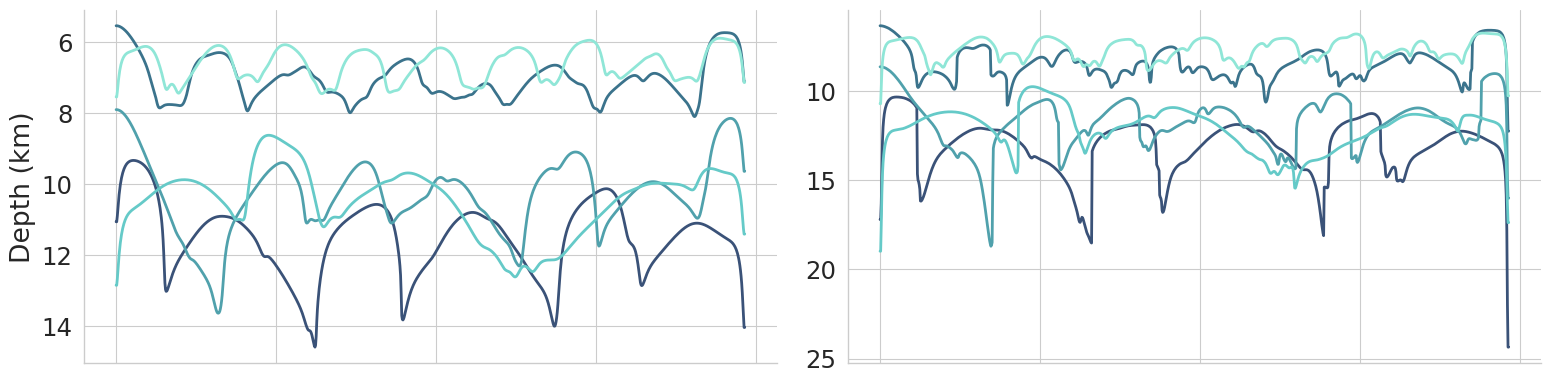

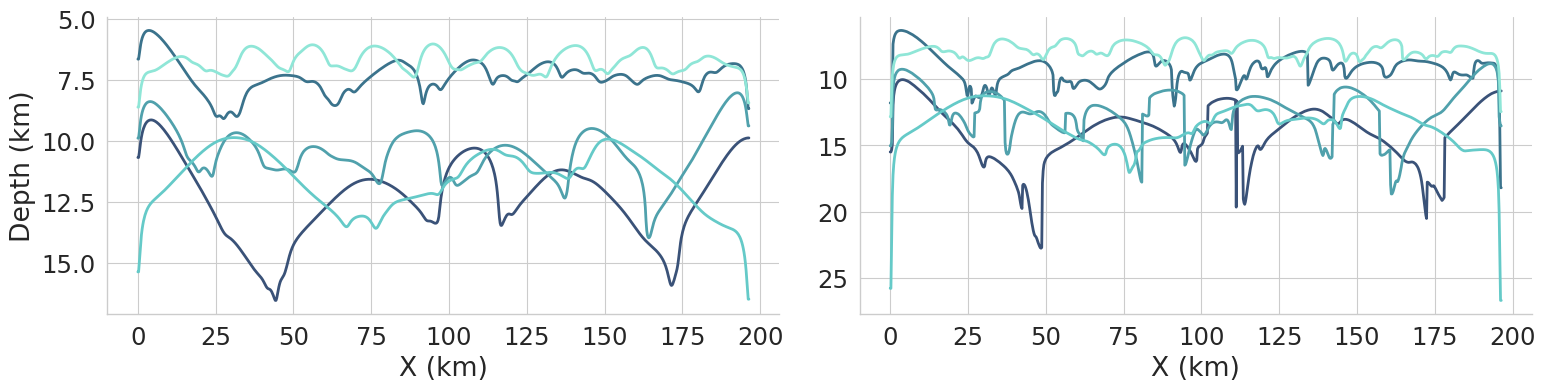

In [11]:
##########################################################################################
hue_order = complex_eut_df["Parameter Folder"].unique()
hue_order = ['varK_constA', 'constK_varA', 'varK_varA', 'shell_complex_rheo', 'shell_tidal']
print(hue_order)
n_lines = len(hue_order)
positions = np.linspace(0.2, 0.85, n_lines)
line_palette = [base_cmap(pos) for pos in positions]
color_lookup = dict(zip(hue_order, line_palette))

for D, sims in complex_D_sims.items():
    shell_eut_df = complex_eut_df[complex_eut_df["D (km)"] == D]
    shell_avg_eut_df = complex_avg_eut_df[complex_avg_eut_df["D (km)"] == D]
    sns.set_context("paper", font_scale=2)
    sns.set_style("whitegrid")

    g = sns.relplot(
    data=shell_eut_df,
    kind="line",                    # Use line instead of scatter
    x="X (km)",
    y="Depth (km)",
    col="Eutectic Type",                   # Facets by column
    hue="Parameter Folder",        # Colors by viscosity
    hue_order=hue_order,
    palette=color_lookup,
    linewidth=2,
    height=4.5,
    aspect=1.4,
    facet_kws={"sharey": False}
    )

    #for ax in g.axes.flat:
    #    print(ax.get_title())
    #    current_col_val = float(ax.get_title().split(" ")[-1])
#
    #    subset_avg = shell_avg_eut_df[shell_avg_eut_df["Eutectic Type"] == current_col_val] # Filter for this column
#
    #    for eutectic_temp, group_data in subset_avg.groupby("Parameter Folder"):
    #        # Plot dashed line
    #        ax.plot(
    #            group_data["Estimated Groundpath (km)"],
    #            group_data["Depth to Eutectic (km)"],
    #            linestyle="--",
    #            color=color_lookup.get(eutectic_temp, "black"), # Fallback to black if key missing
    #            linewidth=2
    #        )
    
    if g._legend:
        g._legend.remove()
        g._legend = None
    
    # --- Final Formatting ---
    for ax in g.axes.flat:
        ax.invert_yaxis()
    if D != 60:
        g.set_xlabels("")
        g.set_xticklabels([])
        g.set(xlim=(-10, shell_eut_df["X (km)"].max()+10))
    
    plt.tight_layout()
    g.set_titles(col_template="")
    g.savefig(f"fig2_complex_D{D}.png", dpi = 200, transparent = True)
    plt.show()